<a href="https://colab.research.google.com/github/joiepark/assignment_esaa/blob/main/261123_%EC%84%B1%EB%8A%A5%EC%B5%9C%EC%A0%81%ED%99%94.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 하이퍼파라미터를 이용한 성능 최적화

### 배치 정규화를 이용한 성능 최적화
* 정규화: 데이터 범위를 사용자가 원하는 범위로 제한하는 것, MinMaxScaler()를 이용해 각 특성 범위(스케일)를 조정한다는 의미로 특성 스케일링(feature scaling)이라고도 함.
* 규제화(regularization): 모델 복잡도를 줄이기 위해 제약을 두는 방법으로, 이 때 제약은 데이터가 네트워크에 들어가기 전에 필터를 적용한 것임. 필터로 걸러진 데이터만 네트워크에 투입되면 빠르고 정확한 결과를 얻을 수 있음.
* 표준화(standardization): 기존 데이터를 평균은 0, 표준편차는 1인 형태의 데이터로 만드는 방법임. 다른 표현으로 표준화 스칼라(standard scalar) 혹은 z-스코어 정규화(z-score normalization)라고도 함.
* 배치 정규화(batch normalization): 기울기 소멸이나 기울기 폭발과 같은 문제를 해결하기 위한 방법임. 일반적으로 이를 위해 손실 함수로 렐루(ReLU)를 사용하거나 초깃값 튜닝, 학습률(learning rate) 등을 조정함. 배치 정규화가 소개된 논문에 따르면, 기울기 소멸과 폭발 원인은 내부 공변량 변화(internal covariance shift) 때문인데, 이것은 네트워크의 각 층마다 활성화 함수가 적용되면서 입력 값들의 분포가 계속 바뀌는 현상을 의미함. 따라서 분산된 분포를 정규분포로 만들기 위해 표준화와 유사한 방식을 미니 배치에 적용해 평균은 0으로, 표준편차는 1로 유지하도록 함.

기울기 소멸: 오차 정보를 역전파시키는 과정에서 기울기가 급격히 0에 가까워져 학습이 되지 않는 현상

기울기 폭발: 학습 과정에서 기울기가 급격히 커지는 현상
* 배치 정규화를 통해 매 단계마다 활성화 함수를 거치면서 데이터셋 분포가 일정해지기 때문에 속도를 향상시킬 수 있지만, 단점도 있음. 첫째, 배치 크기가 작을 때는 정규화 값이 기존 값과 다른 방향으로 훈련될 수 있음. (e.g. 분산이 0이면 정규화 자체가 안 되는 경우가 발생할 수 있음.) 둘째, RNN은 네트워크 계층별로 미니 정규화를 적용해야 하기 때문에 모델이 더 복잡해지면서 비효율적일 수 있음. 이러한 문제들을 해결하기 위한 가중치 수정, 네트워크 구성 변경 등을 수행하지만, 배치 정규화를 적용하면 적용하지 않았을 때보다 일단 성능이 좋아지기 때문에 많이 사용됨.

### 드롭아웃을 이용한 성능 최적화
* 과적합: 훈련 데이터셋을 과하게 학습하는 것
* 일반적으로 훈련 데이터셋은 실제 데이터셋의 부분 집합이므로 훈련 데이터셋에 대해 훈련을 계속한다면 오류는 줄어들지만 테스트 데이터셋에 대한 오류는 어느 순간부터 증가하는데, 이러한 모델을 과적합되어 있다고 함.
* 드롭아웃(dropout): 훈련할 때 일정 비율의 뉴런만 사용하고 나머지 뉴런에 해당하는 가중치는 업데이트하지 않는 방법 (* 매 단계마다 사용하지 않는 뉴런을 바꾸어 가며 훈련시킴.) 즉, 은닉층에 배치된 노드 중 일부를 임의로 끄면서 학습하는 방법이며, 드롭아웃이 적용된 신경망은 일부 노드들은 비활성화되고 남은 노드들로 신호가 연결되는 신경망 형태를 띰. 어떤 노드를 비활성화할지는 학습할 때마다 무작위로 선정되며, 테스트 데이터로 평가할 때는 노드들을 모두 사용하여 출력하되 노드 삭제 비율(드롭아웃 비율)을 곱해 성능을 평가함.
* 드롭아웃을 사용하면 훈련 시간이 길어지는 단점이 있지만, 모델 성능을 향상하기 위해 상당히 자주 쓰는 방법임.

### 배치 정규화와 드롭아웃에 대한 파이토치 예제

In [1]:
## 라이브러리 호출

import torch
import matplotlib.pyplot as plt
import numpy as np

import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

In [2]:
## 데이터셋 내려받기
trainset = torchvision.datasets.FashionMNIST(
    root='../chap08/data/', train=True, download=True, transform=transforms.ToTensor()
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.07MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.9MB/s]


In [3]:
## 데이터셋을 메모리로 가져오기

batch_size = 4
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)

batch_size를 4로 설정해 데이터를 메모리로 가져올 때 한 번에 네 개씩 쪼개서 가져옴.

In [4]:
## 데이터셋 분리

dataiter = iter(trainloader)
images, labels = next(dataiter)

print(images.shape)
print(images[0].shape)
print(labels[0].item())

torch.Size([4, 1, 28, 28])
torch.Size([1, 28, 28])
3


torch.Size에서 첫 번째 출력은 한 번의 배치 크기로 몇 개의 데이터를 가져오는지를 의미하며, 앞에서 batch_size=4를 지정했기 때문에 4를 출력함.
두 번째 출력은 채널을 의미하는 것으로 흑백 이미지는 1을, 컬러 이미지는 3을 출력함.
세 번째 출력은 28x28 (너비x높이) 픽셀 크기의 이미지라는 의미임.

* 기본적으로 파이토치는 이미지 데이터셋을 [배치 크기, 채널, 너비, 높이] 순서대로 저장함. 하지만 이를 맷플롯립으로 출력하기 위해서는 이미지가 [너비, 높이, 채널] 형태여야 함. 즉, 데이터의 형태 변경이 필요한데, 이 때 사용할 수 있는 게 넘파이 라이브러리의 transpose()임.

In [5]:
## 이미지 데이터를 출력하기 위한 전처리

def imshow(img, title):
  plt.figure(figsize=(batch_size * 4, 4))   ## 출력할 개별 이미지의 크기 조정
  plt.axis('off')
  plt.imshow(np.transpose(img, (1, 2, 0)))
  plt.title(title)
  plt.show()

In [6]:
## 이미지 데이터 출력 함수

def show_batch_images(dataloader):
  images, labels = next(iter(dataloader))
  ## 좌표에 이미지 픽셀을 대응시켜 그리드 형태로 출력
  img = torchvision.utils.make_grid(images)
  ## imshow 함수를 사용함으로써 데이터의 형태가 변경됨
  imshow(img, title=[str(x.item()) for x in labels])
  return images, labels

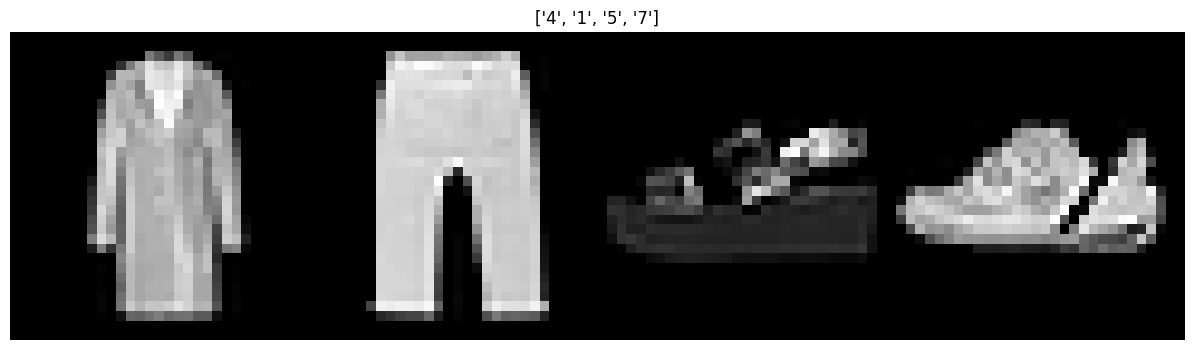

In [7]:
## 이미지 출력

images, labels = show_batch_images(trainloader)

가장 상위에 표시된 숫자는 클래스(레이블)를 의미함.

* nn.BatchNorm1d()는 배치 정규화가 적용되는 부분으로, BatchNorm1d에서 사용되는 파라미터는 특성 개수로 이전 계층의 출력 채널이 됨. 신경망의 층이 깊어질수록 학습할 때 가정했던 입력 분포가 변화해 엉뚱한 학습이 진행될 수 있는데 배치 정규화를 적용해서 입력 분포를 고르게 맞춰줄 수 있음.
* 배치 정규화는 완전연결층과 합성곱층 뒤, 활성화 함수 앞에 위치함.

In [8]:
## 배치 정규화가 적용되지 않은 네트워크

class NormalNet(nn.Module):
  def __init__(self):
    super(NormalNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48),
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.ReLU(),
        nn.Linear(24, 10)
    )

  def forward(self, x):
    x = x.view(x.size(0), -1)
    ## nn.Sequential에서 정의한 계층 추출
    x = self.classifier(x)
    return x

In [9]:
## 배치 정규화가 포함된 네트워크

class BNNet(nn.Module):
  def __init__(self):
    super(BNNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48),
        nn.BatchNorm1d(48),
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.BatchNorm1d(24),
        nn.ReLU(),
        nn.Linear(24, 10)
    )

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = self.classifier(x)
    return x

In [10]:
## 배치 정규화가 적용되지 않은 모델 선언

model = NormalNet()
print(model)

NormalNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): ReLU()
    (2): Linear(in_features=48, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [11]:
## 배치 정규화가 적용된 모델 선언

model_bn = BNNet()
print(model_bn)

BNNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=48, out_features=24, bias=True)
    (4): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [12]:
## 데이터셋 메모리로 불러오기

batch_size = 512
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)

앞에서 메모리를 불러오는 부분은 이미지 출력을 위한 용도로 배치 크기를 4로 설정했으나, 이번에 메모리로 불러오는 것은 학습을 위한 용도로 배치 크기를 512로 설정함.

In [13]:
## 옵티마이저, 손실 함수 지정

loss_fn = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.01)
opt_bn = optim.SGD(model_bn.parameters(), lr=0.01)

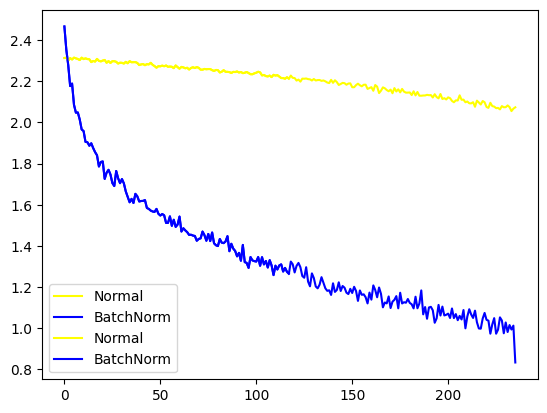

In [14]:
## 모델 학습

loss_arr = []
loss_bn_arr = []
max_epochs = 2

for epoch in range(max_epochs):
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    opt.zero_grad()   ## 배치 정규화가 적용되지 않은 모델의 학습
    outputs = model(inputs)
    loss = loss_fn(outputs, labels)
    loss.backward()
    opt.step()

    opt_bn.zero_grad()   ## 배치 정규화가 적용된 모델의 학습
    outputs_bn = model_bn(inputs)
    loss_bn = loss_fn(outputs_bn, labels)
    loss_bn.backward()
    opt_bn.step()

    loss_arr.append(loss.item())
    loss_bn_arr.append(loss_bn.item())

  plt.plot(loss_arr, 'yellow', label='Normal')
  plt.plot(loss_bn_arr, 'blue', label='BatchNorm')
  plt.legend()

배치 정규화가 적용된 모델과 적용되지 않은 모델 모두 시간이 지날수록 오차가 줄어드는 것을 확인할 수 있음. 하지만 오차가 줄어드는 범위 및 값의 차이가 명백함. 배치 정규화가 적용된 모델의 경우 더 낮은 값으로 안정적인 범위 내에서 줄어들고 있는 것을 확인할 수 있음. 즉, 배치 정규화가 적용된 모델은 에포크가 진행될수록 오차도 줄어들면서 안정적인 학습을 하고 있다고 말할 수 있음.




In [15]:
## 드롭아웃을 알아보기에 앞서 데이터셋의 분포를 출력하기 위한 전처리

N = 50
noise = 0.3

## 훈련 데이터셋이 -1과 1 사이 값을 갖도록 조정
x_train = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
## 훈련 데이터셋 값의 범위가 정규분포를 갖도록 조정
y_train = x_train + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

x_test = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_test = x_test + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

* torch.linspace는 주어진 범위에서 균등한 값을 갖는 텐서를 만들기 위해 사용함. torch.linspace(-1, 1, N)의 의미는 -1과 1 사이의 범위에서 N개의 균등한 값을 갖는 텐서를 생성하겠다는 것임.
* torch.unsqueeze에서 unsqueeze()는 차원을 늘리기 위해 사용함. 따라서 torch.unsqueeze(torch.linspace(-1, 1, N), 1)의 의미는 torch.linspace(-1, 1, N) 텐서의 첫 번째 자리에 차원을 증가시키겠다는 것임,
* torch.normal은 정규분포로부터 무작위 표본 추출을 위해 사용함. torch.normal(평균, 표준편차)를 의미하며 평균은 0, 표준편차는 1이 기본값임.
* torch.zeros는 0 값을 갖는 N X 1 텐서를, torch.ones는 1 값을 갖는 N X 1 텐서를 생성함.

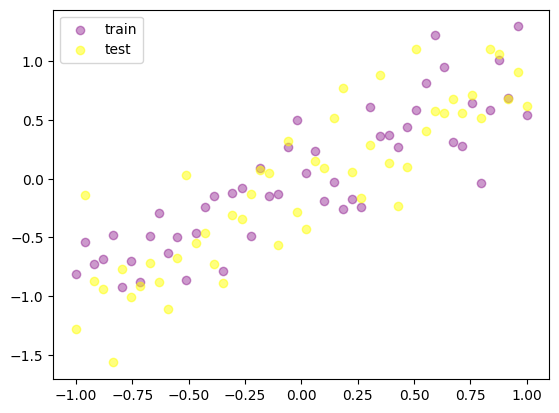

In [16]:
## 데이터 분포를 그래프로 출력

plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple', alpha=0.4, label='train')
plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow', alpha=0.5, label='test')
plt.legend()
plt.show()

훈련과 테스트 데이터가 고르게 분포되어 있음.

In [17]:
## 드롭아웃을 위한 모델 생성

N_h = 100

## 드롭아웃이 적용되지 않은 모델 (수정됨)
model = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1)
)

## 드롭아웃이 적용된 모델
model_dropout = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.Dropout(0.2),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.Dropout(),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1)
)

In [18]:
## 옵티마이저와 손실 함수 지정

opt = torch.optim.Adam(model.parameters(), lr=0.01)
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

/tmp/ipykernel_22545/1207967232.py:34: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' % (epoch, test_loss, test_loss_dropout))


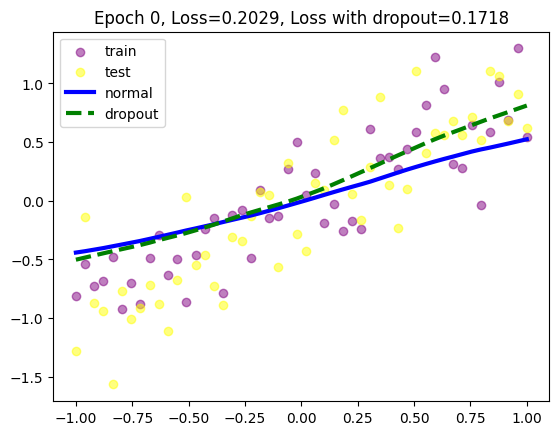

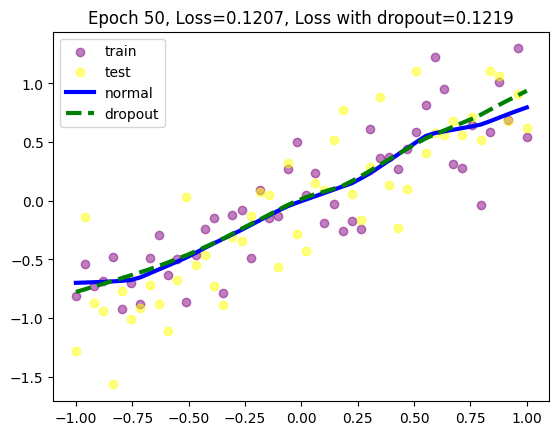

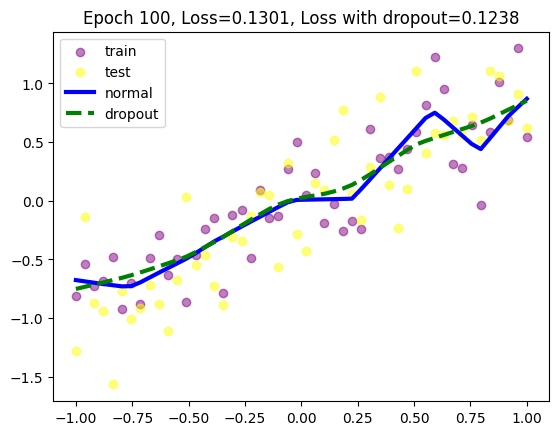

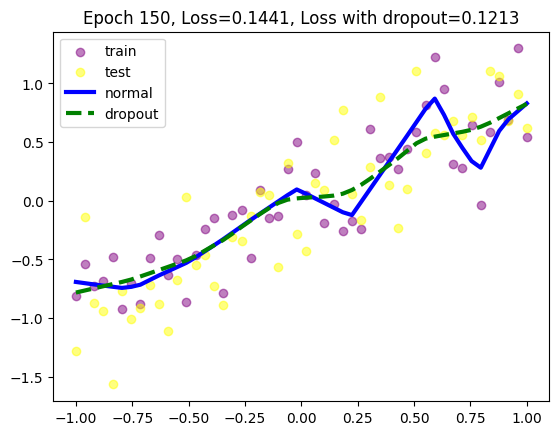

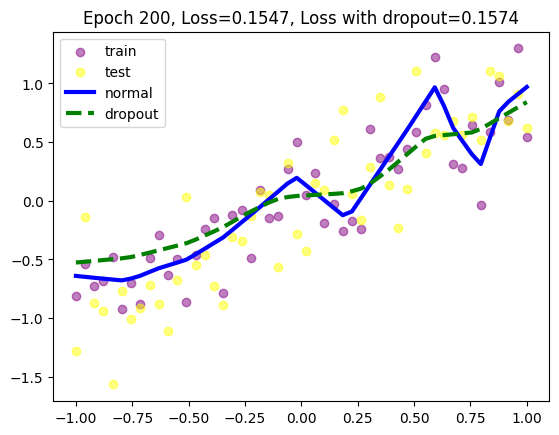

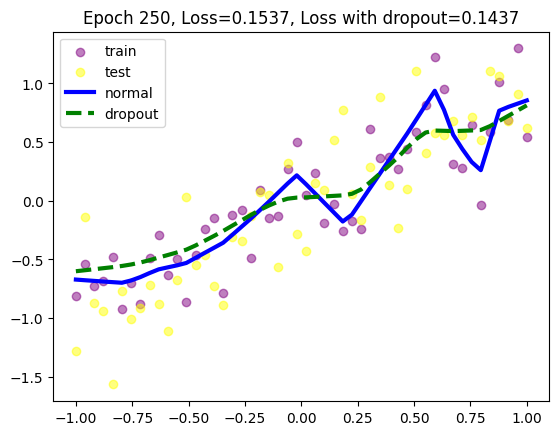

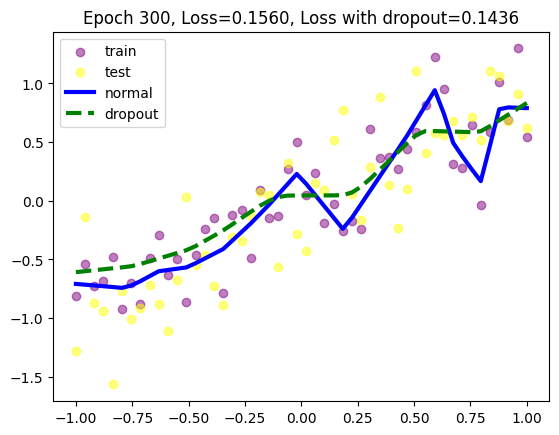

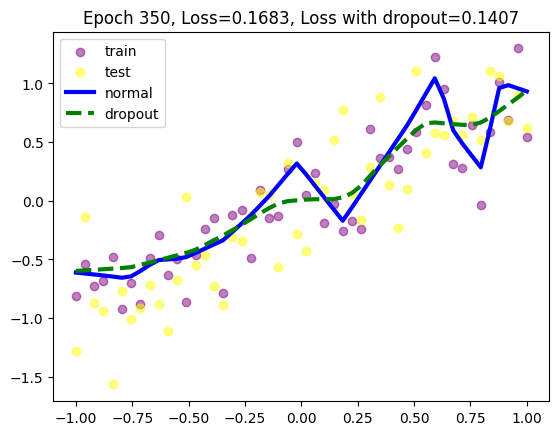

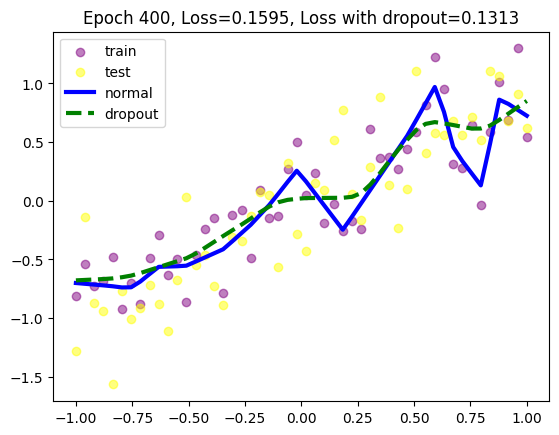

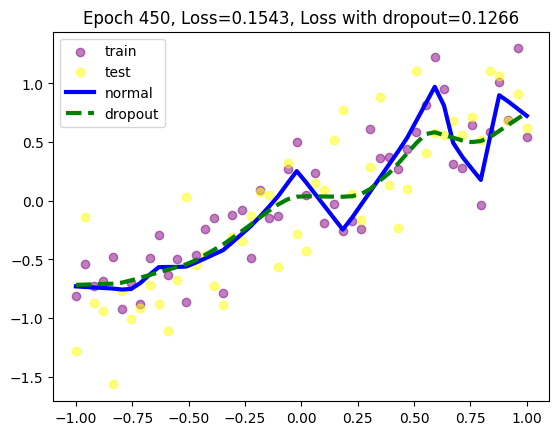

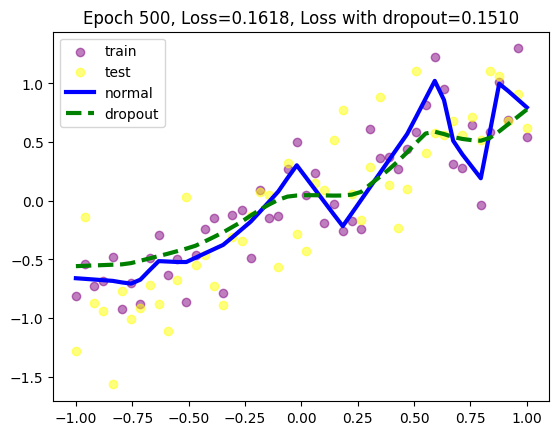

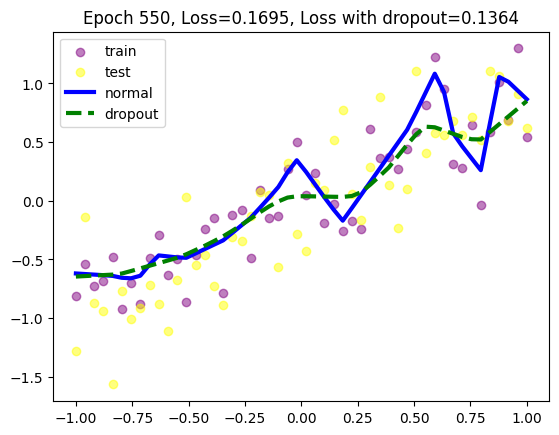

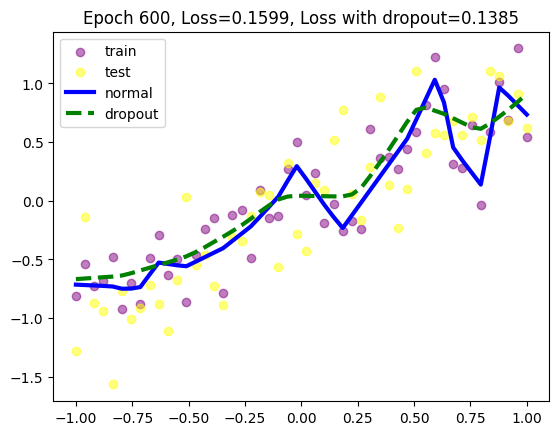

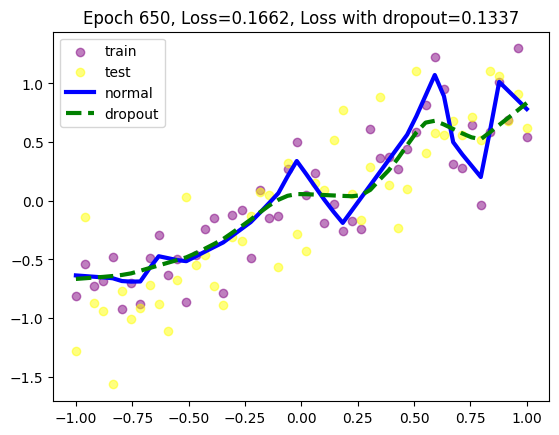

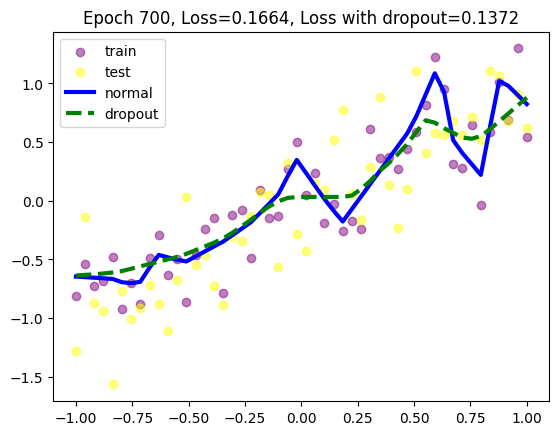

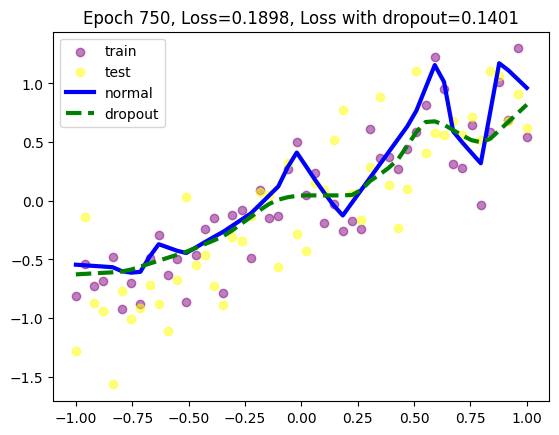

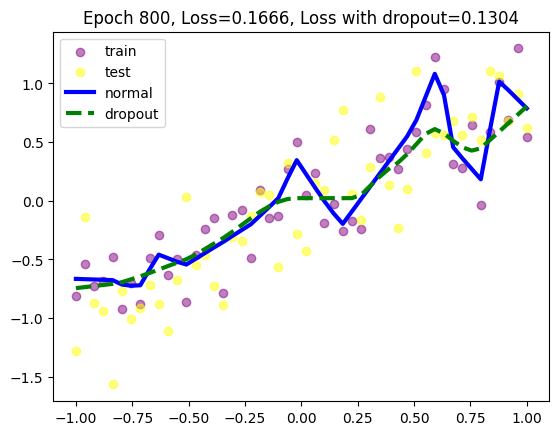

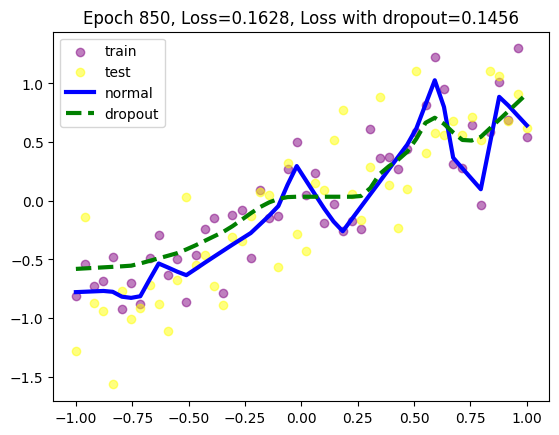

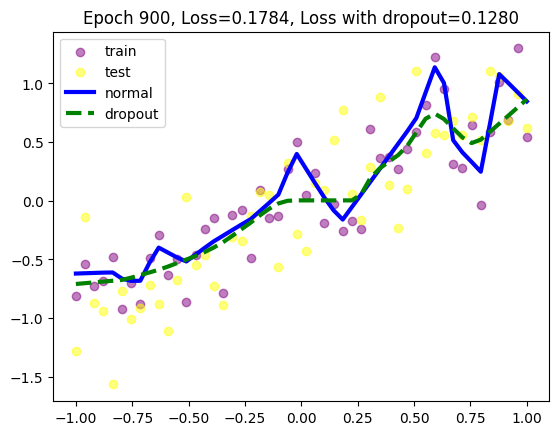

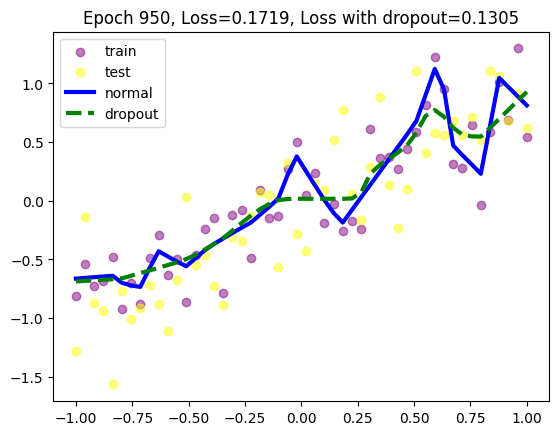

In [19]:
## 모델 학습

max_epochs = 1000
for epoch in range(max_epochs):
  pred = model(x_train)   ## 드롭아웃이 적용되지 않은 모델 학습
  loss = loss_fn(pred, y_train)
  opt.zero_grad()
  loss.backward()
  opt.step()

  pred_dropout = model_dropout(x_train)   ## 드롭아웃이 적용된 모델 학습
  loss_dropout = loss_fn(pred_dropout, y_train)
  opt_dropout.zero_grad()
  loss_dropout.backward()
  opt_dropout.step()

  if epoch % 50 == 0:
    model.eval()
    model_dropout.eval()

    test_pred = model(x_test)
    test_loss = loss_fn(test_pred, y_test)

    test_pred_dropout = model_dropout(x_test)
    test_loss_dropout = loss_fn(test_pred_dropout, y_test)

    plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple', alpha=0.5, label='train')
    plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow', alpha=0.5, label='test')
    ## 파란색 실선으로 x축은 테스트 데이터셋, y축은 드롭아웃이 적용되지 않은 모델의 결과를 그래프로 출력
    plt.plot(x_test.data.numpy(), test_pred.data.numpy(), 'b-', lw=3, label='normal')
    ## 초록색 점선으로 x축은 테스트 데이터셋, y축은 드롭아웃이 적용된 모델의 결과를 그래프로 출력
    plt.plot(x_test.data.numpy(), test_pred_dropout.data.numpy(), 'g--', lw=3, label='dropout')
    ## 에포크, 드롭아웃이 적용되지 않은 모델의 오차, 드롭아웃이 적용된 모델의 오차를 타이틀로 출력
    plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' % (epoch, test_loss, test_loss_dropout))
    plt.legend()
    model.train()
    model_dropout.train()
    plt.pause(0.05)

전반적으로 오차가 줄어드는 범위는 크지 않지만, 드롭아웃을 적용했을 때의 오차가 더 낮은 것을 확인할 수 있음.

출력 결과에서 초록색 점선(드롭아웃이 적용된 모델)과 파란색 실선(드롭아웃이 적용되지 않은 모델)의 차이가 크지 않아 보일 수 있으나 실제로는 큰 차이가 있는 상태임. 훈련 횟수가 늘어날수록 파란색 실선은 가장자리의 자주색 점들을 찾아가고 있음. 문제는 자주색 선이 훈련 데이터셋을 의미한다는 것이고, 이것은 다른 의미로 과적합 현상을 보이고 있다는 것임. 과적합이 발생하는 모델은 훈련 데이터에 대한 정확도는 높을 수 있지만, 새로운 데이터, 즉 검증 데이터나 테스트 데이터에 대해서는 제대로 동작하지 않는 문제가 있음. 이와 같이 과적합 현상을 방지하기 위해 드롭아웃을 사용하며, 초록색 점선 그래프에서는 과적합이 발생하지 않는 것을 알 수 있음.

### 조기 종료를 이용한 성능 최적화
* 조기 종료(early stopping)는 뉴럴 네트워크가 과적합을 회피하는 규제 기법임. 훈련 데이터와 별도로 검증 데이터를 준비하고, 매 에포크마다 검증 데이터에 대한 오차(validation loss)를 측정해 모델의 종료 시점을 제어함.
* 과적합이 발생하기 전까지 학습에 대한 오차와 검증에 대한 오차 모두 감소하지만, 과적합이 발생하면 훈련 데이터셋에 대한 오차는 감소하는 반면 검층 데이터셋에 대한 오차는 증가함. 따라서 조기 종료는 검증 데이터셋에 대한 오차가 증가하는 시점에서 학습을 멈추도록 조정함.
* 조기 종료는 학습을 언제 종료시킬지 결정할 뿐, 최고의 성능을 갖는 모델을 보장하지는 않음을 유의해야 함.

In [20]:
## 라이브러리 호출

import torch
import torch.nn as nn
import torch.optim as optim
## 사전 학습된 모델을 이용하고자 할 때 사용하는 라이브러리
import torchvision.models as model
from torchvision import transforms, datasets

import matplotlib
import matplotlib.pyplot as plt
import time
import argparse
from tqdm import tqdm
## 출력 그래프에서 격자로 숫자 범위가 눈에 잘 띄도록 하는 스타일
matplotlib.style.use('ggplot')

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [21]:
## 데이터셋 전처리

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [22]:
!git clone https://github.com/gilbutITbook/080289.git

train = './080289/chap08/data/archive/train'
test = './080289/chap08/data/archive/test'

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 24.55 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [23]:
## 데이터셋 가져오기

train_dataset = datasets.ImageFolder(root=train, transform=train_transform)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataset = datasets.ImageFolder(root=test, transform=val_transform)
val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

In [24]:
## 모델 생성

def resnet50(pretrained=True, requires_grad=False):
  model = models.resnet50(progress=True, pretrained=pretrained)
  if requires_grad == Fale:
    ## 파라미터를 고정해 backward() 중에 기울기가 계산되지 않도록 함
    for param in model.parameters():
      param.requires_grad = False
  elif requires_grad == True:
    ## 파라미터 값이 backward() 중에 기울기 계산에 반영됨
    for param in model.parameters():
      param.requires_grad = True
  ## 마지막 분류를 위한 계층은 학습을 진행함
  model.fc = nn.Linear(2048, 2)
  return model

* 파이토치에서 조기 종료와 함께 사용되는 것으로 학습률 감소(learning rate decay)라는 것이 있음. 이는 학습률에 대한 값을 고정시켜서 모델을 학습시키는 것이 아니라, 학습이 진행되는 과정에서 학습률을 조금씩 낮추어주는 성능 튜닝 기법 중 하나임.
* 학습률 감소는 학습률 스케줄러(learning rate scheduler)라는 것을 사용하는데, 주어진 'patience' 횟수만큼 검증 데이터셋에 대한 오차 감소가 없으면 역시 주어진 'factor'만큼 학습률을 감소시켜서 모델 학습의 최적화가 가능하도록 도와줌.
* torch.optim.lr_scheduler.ReduceLR0nPlateau()는 학습 과정에서 모델 성능에 대한 개선이 없을 경우 학습률을 factor배로 감소시킴.
1. optimizer: 파라미터(가중치)를 갱신시키는 부분으로, 여기에서는 아담(optim.Adam)을 사용함.
2. mode: 언제 학습률을 조정할지에 대한 기준이 되는 값임. 만약 검증 데이터셋에 대한 오차(val_loss)를 기준으로 사용하면 오차가 더 이상 감소되지 않을 때 학습률을 조정하게 됨. 이때 오차 값이 최소가 되어야 하는지, 최대가 되어야 하는지 알려주는 파라미터가 바로 mode임. (e.g. 학습률 조정의 기준이 되는 값을 모델의 정확도(val_acc)로 사용하면 값이 클수록 좋기 때문에 'max'를 지정하고, 모델의 오차(val_loss)로 사용할 경우 작을수록 좋으므로 'min'을 지정함.)
3. patience: 학습률을 업데이트하기 전에 몇 번의 에포크를 기다려야 하는지 결정하는 것임.
4. factor: 학습률을 얼마나 감소시킬지 지정하는 파라미터임. 새로운 학습률은 기존 학습률 * factor가 됨.
5. min_lr: 학습률의 하한선을 지정함.
6. verbose: 조기 종료의 시작과 끝을 출력하기 위해 사용함. 1로 설정할 경우 조기 종료가 적용되면 적용되었다고 화면에 출력되지만, 0으로 설정할 경우 아무런 출력 없이 학습을 종료함.

In [25]:
class LRScheduler():
  def __init__(self, optimizer, patience=5, min_lr=1e-6, factor=0.5):
    self.optimizer = optimizer
    self.patience = patience
    self.min_lr = min_lr
    self.factor = factor
    self.lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        self.optimizer,
        mode='min',
        patience=self.patience,
        factor=self.factor,
        min_lr=self.min_lr,
        verbose=True
    )
  def __call__(self, val_loss):
    self.lr_scheduler.step(val_loss)

* patience는 오차 개선이 없다고 바로 종료하지 않고 개선이 없는 에포크를 얼마나 기다려줄지 지정함.
* delta는 오차가 개선되고 있다고 판단하기 위한 최소 변화량을 나타냄. 변화량이 delta보다 적다면 개선이 없다고 판단함.

In [26]:
## 조기 종료

class EarlyStopping():
  def __init__(self, patience=5, verpose=False, delta=0, path='../chap08/data/checkpoint.pt'):
    self.patience = patience
    self.verbose = verbose
    self.counter = 0
    ## 검증 데이터셋에 대한 오차 최적화 값(오차가 가장 낮은 값)
    self.best_score = None
    ## 조기 종료를 의미하며 default=False
    self.early_stop = False
    ## np.Inf(infinity)는 넘파이에서 무한대를 표현
    self.val_loss_min = np.Inf
    self.delta = delta
    ## 모델이 저장될 경로
    self.path = path

  def __call__(self, val_loss, model):
    ## 에포크만큼 학습이 반복되면서 best_loss가 갱신되고, best_loss에 진전이 없으면 조기 종료한 후 모델을 저장
    score =-val_loss
    if self.best_score is None:
      self.best_score = score
      self.save_checkpoint(val_loss, model)
    elif score < self.best_score + self.delta:
      self.counter += 1
      print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
      if self.counter >= self.patience:
        self.early_stop = True
    else:
      self.best_score = score
      self.save_checkpoint(val_loss, model)
      self.counter=0

    def save_checkpoint(self, val_loss, model):
      if self.verbose:
        print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...')
      torch.save(model.state_dict(), self.path)
      self.val_loss_min = val_loss

* 원하는 인수 값을 추가할 때 parser.add_argument()는 인수 개수만큼 만들어줌.
1. 첫 번쩨 파라미터: 옵션 문자열의 이름으로 명령을 실행할 때 사용함.
2. dest: 입력 값이 저장되는 변수임.
3. action: action을 store_true로 지정하면 입력 값을 dest 파라미터에 의해 생성된 변수에 저장함.

In [27]:
## 인수 값 생성

parser = argparse.ArgumentParser()
parser.add_argument('--lr-scheduler', dest='lr_scheduler', action='store_true')
parser.add_argument('--early-stopping', dest='early_stopping', action='store_true')
args, unknown = parser.parse_known_args()
args = vars(args)

In [28]:
## 사전 훈련된 모델의 파라미터 확인

import torchvision.models as models

## CPU 사용하는지 GPU 사용하는지 검사
print(f"Computationd device: {device}\n")
## 사전 훈련된 ResNet50 사용
model = models.resnet50(pretrained=True).to(device)
total_params = sum(p.numel() for p in model.parameters())  ## 총 파라미터 수
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad  ## 학습 가능한 파라미터 수
)
print(f"{total_trainable_params:,} training parameters.")

Computationd device: cpu



/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 91.3MB/s]


25,557,032 total parameters.
25,557,032 training parameters.


In [29]:
## 옵티마이저와 손실 함수 지정

lr = 0.001
epochs = 100
optimizer = optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

In [30]:
## 오차, 정확도 및 모델의 이름에 대한 문자열

loss_plot_name = 'loss'
acc_plot_name = 'accuracy'
model_name = 'model'

In [31]:
## 오차, 정확도 및 모델의 이름에 대한 문자열

if args['lr_scheduler']:
  print('INFO: Initializing learning rate scheduler')
  lr_scheduler = LRScheduler(optimizer)
  loss_plot_name = 'lrs_loss'
  acc_plot_name = 'lrs_accuracy'
  model_name = 'lrs_model'
if args['early_stopping']:
  print('INFO: Initializing early stopping')
  early_stopping = EarlyStopping()
  loss_plot_name = 'es_loss'
  acc_plot_name = 'es_accuracy'
  model_name = 'es_model'

In [32]:
# 모델 학습 함수

def training(model, train_dataloader, train_dataset, optimizer, criterion):
  print('Training')
  model.train()
  train_running_loss=0.0
  train_running_correct = 0
  counter = 0
  total = 0
  prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataset)/train_dataloader.batch_size))
  for i, data in prog_bar:
    counter += 1
    data, target = data[0].to(device), data[1].to(device)
    total += target.size(0)
    optimizer.zero_grad()
    outputs = model(data)
    loss = criterion(outputs, target)
    train_running_loss += loss.item()
    _, preds = torch.max(outputs.data, 1)
    train_running_correct += (preds == target).sum().item()
    loss.backward()
    optimizer.step()

  train_loss = train_running_loss / counter
  train_accuracy = 100. * train_running_correct / total
  return train_loss, train_accuracy

In [35]:
## 모델 검증 함수

def validate(model, test_dataloader, val_dataset, criterion):
  print('Validating')
  model.eval()
  val_running_loss = 0.0
  val_running_correct = 0
  counter = 0
  total = 0
  prog_bar = tqdm(enumerate(test_dataloader), total=int(len(val_dataset)/test_dataloader.batch_size))
  with torch.no_grad():
    for i, data in prog_bar:
      counter += 1
      data, target = data[0].to(device), data[1].to(device)
      total += target.size(0)
      outputs = model(data)
      loss = criterion(outputs, target)

      val_running_loss += loss.item()
      _, preds = torch.max(outputs.data, 1)
      val_running_correct += (preds == target).sum().item()

    val_loss = val_running_loss / counter
    val_accuracy = 100. * val_running_correct / total
    return val_loss, val_accuracy

In [ ]:
## 모델 학습

train_loss, train_accuracy = [], []

val_loss, val_accuracy = [], []

start = time.time()
for epoch in range(epochs):
  train_epoch_loss, train_epoch_accuracy = training(model, train_dataloader, train_dataset, optimizer, criterion)
  val_epoch_loss, val_epoch_accuracy = validate(model, val_dataloader, val_dataset, criterion)
  train_loss.append(train_epoch_loss)
  train_accuracy.append(train_epoch_accuracy)
  val_loss.append(val_epoch_loss)
  val_accuracy.append(val_epoch_accuracy)
  if args['lr_scheduler']:
    lr_scheduler(val_epoch_loss)
  if args['early_stopping']:
    early_stopping(val_epoch_loss, model)
    if early_stopping.early_stop:
      print("Early stopping")
      break
  print(f"Epoch: {epoch+1} Train Loss: {train_epoch_loss:.4f} Train Acc: {train_epoch_accuracy:.2f}")
  print(f"Epoch: {epoch+1} Val Loss: {val_epoch_loss:.4f} Val Acc: {val_epoch_accuracy:.2f}")
end = time.time()
print(f"Training time: {(end-start)/60:.3f} minutes")

Training


16it [05:15, 19.74s/it]


Validating


16it [01:30,  5.66s/it]


Epoch: 1 Train Loss: 0.5919 Train Acc: 72.69
Epoch: 1 Val Loss: 0.7303 Val Acc: 59.60
Training


16it [05:19, 19.95s/it]


... (16 outputs left out)

Validating


16it [01:31,  5.69s/it]


Epoch: 6 Train Loss: 0.2853 Train Acc: 87.75
Epoch: 6 Val Loss: 0.5745 Val Acc: 79.80
Training


  7%|▋         | 1/15 [00:20<04:47, 20.55s/it]

In [ ]:
## 모델 학습 결과 출력

print('Saving loss and accuracy plots..')
plt.figure(figsize=(10, 7))
plt.plot(train_accuracy, color='green', label='train accuracy')
plt.plot(val_accuracy, color='blue', label='validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(f"../chap08/img/{acc_plot_name}.png")
plt.show()
plt.plot(train_loss, color='orange', label='train loss')
plt.plot(val_loss, color='red', label='validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(f"../chap08/img/{loss_plot_name}.png")
plt.show()

print('Saving model..')
torch.save(model.state_dict(), f"../chap08/img/{model_name}.pth")
print('TRAINING COMPLETE')

1. 어떤 인수도 적용하지 않았을 때의 실행 결과

정확도의 경우 위아래로 많은 변동이 있음. 정확도가 10% 이상 차이가 나는 일부 에포크 사이는 기복이 매우 심함. 오차에 대한 그래프도 크게 다르지 않음. 특히 에포크 10 이후부터는 검증 데이터셋에 대한 오차가 미세한 차이로 우상향하는 것을 볼 수 있음. 이것은 모델이 과적합되기 시작했으며 적절한 훈련을 계속하려면 학습률 값을 줄여야 한다는 것을 보여줌.

2. 학습률 감소와 관련된 인수를 입력했을 때의 실행 결과

정확도를 보여주는 그래프가 앞에서 보았던 그래프와는 다르게 완만한 곡선 형태를 보여줌. 또한 훈련이 종료된 시점의 검증 데이터셋에 대한 정확도도 높게 나타나고 있음. 그리고 오차 그래프의 경우 그래프가 우상향하는 현상도 없어짐 즉, 학습률 스케줄러가 성능 향상에 어느 정도 기여했음을 의미함. 그러나 자세히 관찰하면 검증 데이터셋에 대한 오차가 에포크 20 정도에서도 정체되기 시작함. 즉, 에포크를 30 정도만 수행해도 모델 훈련에 여전히 좋은 결과를 얻을 수 있을 것이라고 추측 가능함.

3. 조기 종료 인수를 적용했을 때의 결과

다섯 번째 에포크부터 조기 종료가 수행되고 있기 때문에 실제로 학습은 네 번째 에포크까지만 수행되었다고 볼 수 있음. 조기 종료로 인해 모델이 제대로 학습하지 못할 수 있음. 실제로 검증 데이터셋에 대한 정확도 그래프가 위아래로 오가면서 불안정한 결과를 출력하고 있음. 그렇다고 학습을 이어나간다고 해서 더 좋은 결과를 얻을 수 있다는 보장도 없음. 따라서 그래프가 의미하는 내용을 잘 이해하고 적절한 성능 향상 방안을 적용해야 함. 앞에서 검증 데이터셋에 대한 정확도는 좋지 않지만, 오차는 많이 낮아진 것을 확인할 수 있음. 따라서 정확도만 보고 조기 종료가 효과가 없다고 판단하기에는 무리가 있음.

* 분명한 것은 학습률 스케줄러를 이용한 학습률 조정 기법과 조기 종료가 모델 성능을 향상시키는 데에는 도움이 된다는 것임. (* 조기 종료의 경우에는 성능 향상보다는 자원의 효율화) 단 모든 모델에 일괄 적용이 아닌 기존의 출력된 그래프를 해석해 어떤 성능 기법을 적용할지 결정하는 것이 중요함.